In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure screenshots directory exists to st\ore report visuals
os.makedirs("../screenshots", exist_ok=True)

# Load the dataset created by your preprocess script
df = pd.read_csv("../data/processed/heart_cleaned.csv")

print(f"Dataset Shape: {df.shape}")
df.info()

Dataset Shape: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


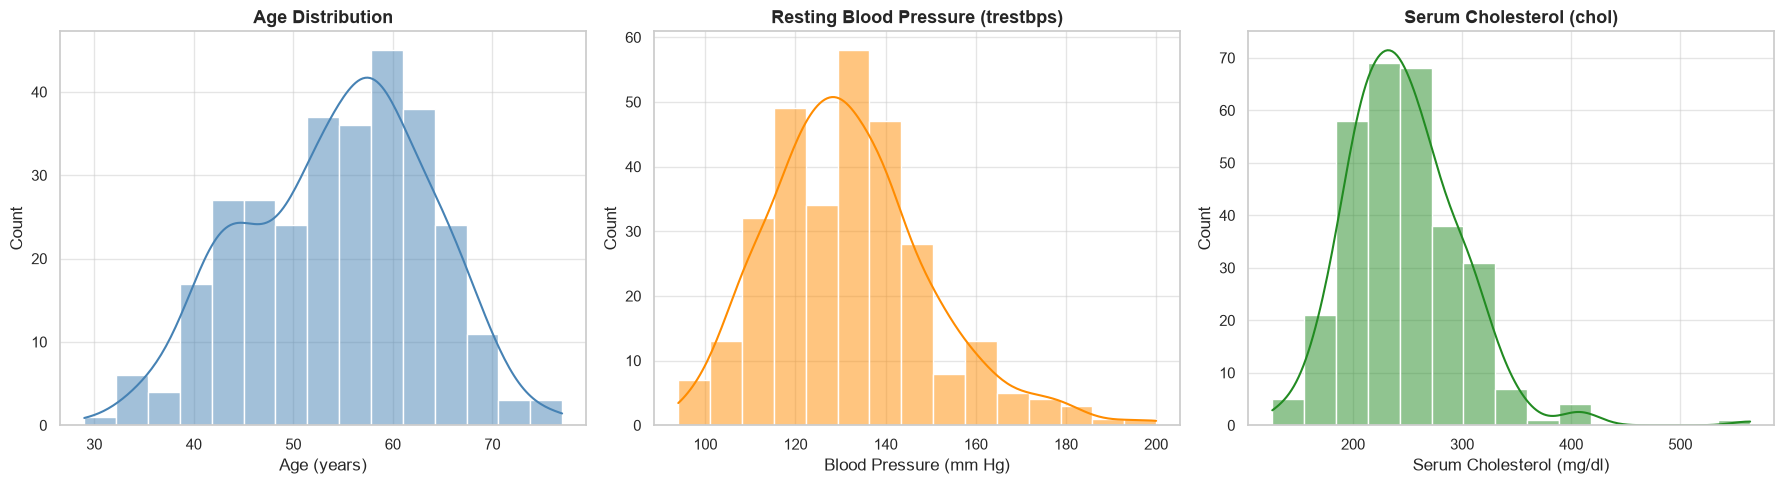

In [3]:
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age
sns.histplot(data=df, x="age", kde=True, ax=axes[0], color="steelblue", bins=15)
axes[0].set_title("Age Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Age (years)")

# Resting Blood Pressure
sns.histplot(data=df, x="trestbps", kde=True, ax=axes[1], color="darkorange", bins=15)
axes[1].set_title("Resting Blood Pressure (trestbps)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Blood Pressure (mm Hg)")

# Serum Cholesterol
sns.histplot(data=df, x="chol", kde=True, ax=axes[2], color="forestgreen", bins=15)
axes[2].set_title("Serum Cholesterol (chol)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Serum Cholesterol (mg/dl)")

plt.tight_layout()
plt.savefig("../screenshots/eda_feature_distributions.png", dpi=300)
plt.show()

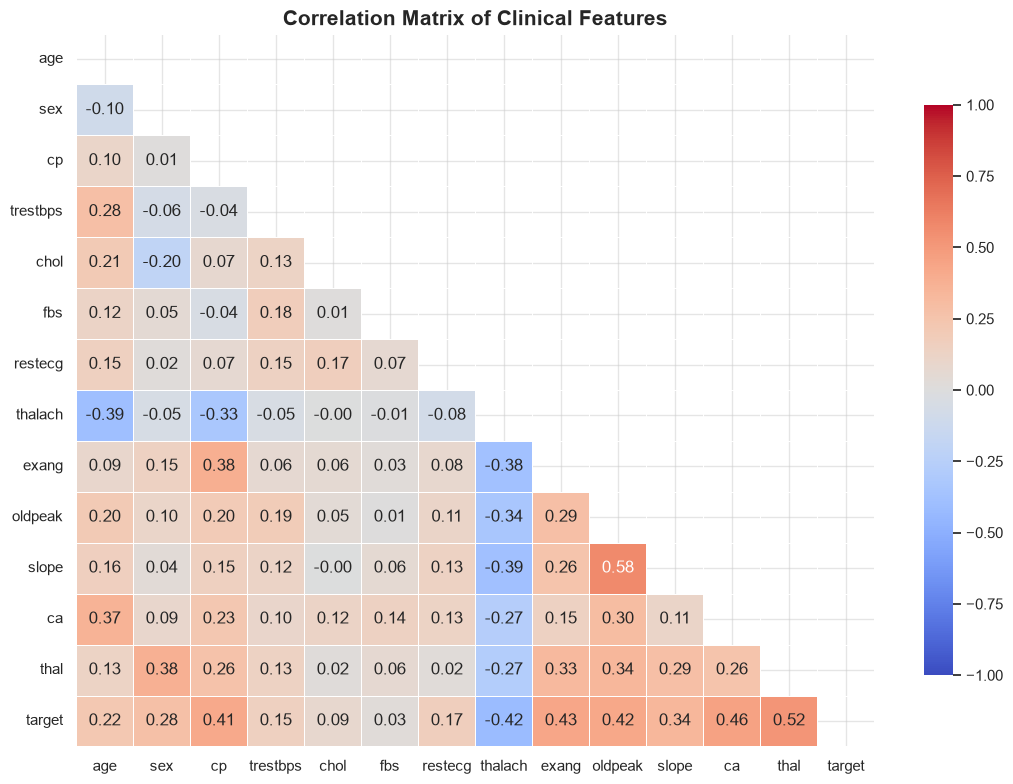

In [4]:
plt.figure(figsize=(11, 8))
corr_matrix = df.corr()

# Mask upper triangle for visual clarity
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix of Clinical Features", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("../screenshots/eda_correlation_heatmap.png", dpi=300)
plt.show()

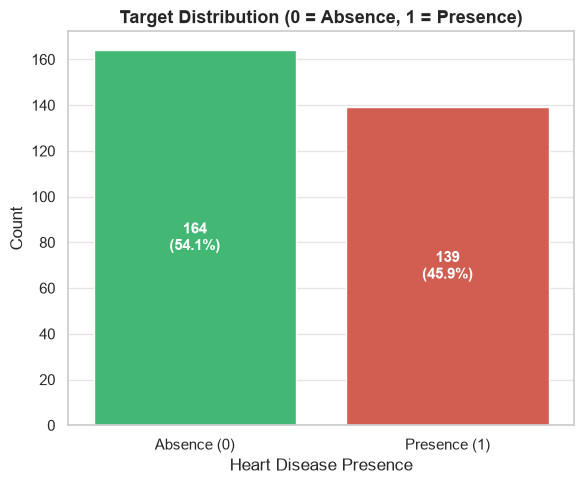

In [7]:
plt.figure(figsize=(6, 5))

# Assign 'target' to hue and disable the redundant legend
ax = sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette=["#2ecc71", "#e74c3c"],
    legend=False
)

plt.title("Target Distribution (0 = Absence, 1 = Presence)", fontsize=13, fontweight="bold")
plt.xlabel("Heart Disease Presence")
plt.ylabel("Count")
plt.xticks(ticks=[0, 1], labels=["Absence (0)", "Presence (1)"])

# Annotate percentages on top of bars
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / total) * 100
    ax.annotate(
        f"{count}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
        ha='center', va='center', color='white', fontweight='bold', fontsize=11
    )

plt.tight_layout()
plt.savefig("../screenshots/eda_class_balance.png", dpi=300)
plt.show()